# DS-09 | Multi-Armed Bandit — Selección Óptima bajo Incertidumbre
## 2 · Supply Chain Adaptation — Selección Dinámica de Proveedor Alternativo
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 09 de 10  
**Dataset:** 120 proveedores SC Perú — mismos que DS-07/DS-08 — brazos = alternativas para SKU crítico  
**Fuentes:** Calibración SUNAT importaciones 2022  
**Aplicación:** Cuando DS-08 detecta que el proveedor habitual falla, MAB elige el mejor alternativo en tiempo real

---

### El problema de negocio

DS-08 acaba de detectar que el proveedor P-07 (importado, LT=22 días) tiene un
patrón anómalo de entrega. El equipo de procurement necesita activar un
**proveedor alternativo** para el SKU crítico SKU-14.

Hay 8 proveedores alternativos disponibles. Sus características reales son:

- LT entre 4 y 18 días
- Precio FOB entre 42 y 78 USD/unidad
- Fill rate histórico entre 0.78 y 0.96

**El problema:** no sabemos con certeza cuál es el mejor.
Las características históricas son una guía, pero la **recompensa real**
(utilidad: LT corto + precio bajo + fill rate alto) solo se observa
cuando realmente hacemos el pedido.

**MAB resuelve exactamente esto:** en cada semana que necesitamos activar
al alternativo, el bandit elige cuál probar — aprendiendo cuál es el mejor
sin desperdiciar pedidos en opciones claramente inferiores.

### Función de utilidad — la recompensa del brazo

Cada proveedor $k$ genera una recompensa compuesta:

$$u_k(t) = w_{LT}\left(1 - \frac{LT_k(t)}{LT_{max}}\right) + w_{P}\left(1 - \frac{P_k(t)}{P_{max}}\right) + w_{FR} \cdot FR_k(t) + \varepsilon_k(t)$$

Con pesos $w_{LT}=0.40$, $w_P=0.35$, $w_{FR}=0.25$ — ponderación del equipo de SC.

El bandit no conoce $\mu_k = \mathbb{E}[u_k(t)]$ — los aprende jugando.

### Conexión con la cadena DS-02 → DS-09

| Modelo | Aporte |
|---|---|
| DS-02 BOCPD | Detecta cuándo el LT del proveedor cambia de régimen |
| DS-03 GCN | Clasifica el riesgo del proveedor en la red |
| DS-04 CP | Garantiza los intervalos de predicción del LT |
| DS-05 SHAP | Explica qué feature domina el costo de SS |
| DS-06 BO | Optimiza (SS*, ROP*, Q*) en el nuevo régimen |
| DS-07 SSL | Propaga el riesgo a proveedores no auditados |
| DS-08 AE | Detecta que el proveedor habitual es anómalo → **activa DS-09** |
| **DS-09 MAB** | **Selecciona el mejor alternativo aprendiendo en tiempo real** |

### Ejercicio a mano — 3 proveedores alternativos, 5 semanas

Proveedores: PA (μ=0.72), PB (μ=0.65), PC (μ=0.58). Semanas:

| Sem | Algoritmo | Elegido | u observada | μ̂_A | μ̂_B | μ̂_C | UCB_A | UCB_B | UCB_C |
|---|---|---|---|---|---|---|---|---|---|
| 1 | Init | PA | 0.74 | 0.740 | — | — | — | — | — |
| 2 | Init | PB | 0.62 | 0.740 | 0.620 | — | — | — | — |
| 3 | Init | PC | 0.55 | 0.740 | 0.620 | 0.550 | — | — | — |
| 4 | UCB1 | PB | 0.68 | 0.74+√(ln4/1) | 0.62+√(ln4/1) | 0.55+√(ln4/1) | 2.52 | 2.40 | 2.33 |
| 5 | UCB1 | PA | 0.71 | 0.74+√(ln5/2) | 0.65+√(ln5/1) | 0.55+√(ln5/1) | 1.64 | 2.32 | 2.27 |

PA es el mejor — UCB1 lo converge en pocas semanas sin necesidad de una auditoría costosa.


---
## Marco Teórico — MAB para Selección de Proveedores

### Brazos = proveedores alternativos para un SKU crítico

Cuando el proveedor habitual es declarado anómalo por DS-08:
- **Brazo $k$:** proveedor alternativo $k$ ($k = 1, \ldots, K$)
- **Turno $t$:** semana $t$ en que se activa al alternativo
- **Recompensa $r_t$:** utilidad observada del pedido realizado

### Actualización bayesiana de la utilidad

Tras $N_k$ pedidos al proveedor $k$:

$$\hat{\mu}_k = \frac{1}{N_k} \sum_{t: a_t=k} u_k(t)$$

**Thompson Sampling** muestrea:
$$\tilde{\mu}_k \sim \mathcal{N}\!\left(\hat{\mu}_k,\ \frac{\hat{\sigma}_k^2}{N_k}\right)$$

y elige $a_t = \arg\max_k \tilde{\mu}_k$.

### Regret operativo — el costo de explorar

Cada turno en que se elige un proveedor subóptimo, se incurre en:

$$\text{costo\_exploración}(t) = (\mu^* - \mu_{a_t}) \times D \times P_{FOB}$$

donde $D$ es la demanda semanal y $P_{FOB}$ es el precio del insumo.
Minimizar el regret = minimizar el sobrecosto de la selección dinámica.

### Contextual Bandit — extensión con features del proveedor

Si el contexto $x_t$ (temporada, volumen de pedido, urgencia) afecta
cuál proveedor es mejor, se usa un **Contextual Bandit**:

$$\mu_k(x_t) = \theta_k^\top x_t + \varepsilon_k$$

LinUCB es el algoritmo estándar:
$$a_t = \arg\max_k \left[\hat{\theta}_k^\top x_t + \alpha \sqrt{x_t^\top A_k^{-1} x_t}\right]$$

donde $A_k = X_k^\top X_k + \lambda I$ es la matriz de regularización del brazo $k$.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'eg'       : '#185FA5',
    'ucb'      : '#BA7517',
    'ts'       : '#1D9E75',
    'oracle'   : '#E24B4A',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
    'peru_r'   : '#C8102E',
}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':PALETTE['bg'],
    'axes.grid':True,'grid.color':PALETTE['grid'],'grid.linewidth':0.5,
    'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
})
print('Imports OK — Supply Adaptation | MAB para selección de proveedor alternativo SC Perú')

Imports OK — Supply Adaptation | MAB para selección de proveedor alternativo SC Perú


In [2]:
# ── 1. DATOS — 8 proveedores alternativos para SKU crítico ───────────
rng = np.random.default_rng(42)
T   = 60   # semanas de operación con alternativo

# ── Características de los 8 proveedores alternativos ─────────────────
# (calibradas con datos SUNAT 2022 y estructura de DS-07)
PROV_PARAMS = [
    {'name':'PA-Lima',    'lt_mean':5.0, 'lt_std':0.8, 'price':48.0, 'fr_mean':0.94},
    {'name':'PB-Callao',  'lt_mean':6.0, 'lt_std':1.0, 'price':45.0, 'fr_mean':0.91},
    {'name':'PC-China',   'lt_mean':14.0,'lt_std':3.5, 'price':38.0, 'fr_mean':0.87},
    {'name':'PD-Taiwan',  'lt_mean':12.0,'lt_std':2.8, 'price':41.0, 'fr_mean':0.89},
    {'name':'PE-Mexico',  'lt_mean':9.0, 'lt_std':2.0, 'price':52.0, 'fr_mean':0.92},
    {'name':'PF-Colombia','lt_mean':7.0, 'lt_std':1.5, 'price':55.0, 'fr_mean':0.90},
    {'name':'PG-Brasil',  'lt_mean':8.0, 'lt_std':1.8, 'price':50.0, 'fr_mean':0.88},
    {'name':'PH-Chile',   'lt_mean':6.5, 'lt_std':1.2, 'price':47.0, 'fr_mean':0.93},
]

K = len(PROV_PARAMS)

# ── Función de utilidad por pedido ────────────────────────────────────
LT_MAX  = max(p['lt_mean'] for p in PROV_PARAMS) + 5   # 19 días
P_MAX   = max(p['price']   for p in PROV_PARAMS) + 5   # 60 USD
W_LT, W_P, W_FR = 0.40, 0.35, 0.25

def utility(lt, price, fr):
    """Utilidad compuesta: cuanto mayor, mejor el proveedor."""
    return W_LT*(1 - lt/LT_MAX) + W_P*(1 - price/P_MAX) + W_FR*fr

# ── Pregenerar recompensas (T semanas por proveedor) ─────────────────
REWARDS_SC = np.zeros((K, T))
for k, p in enumerate(PROV_PARAMS):
    lt_obs    = rng.normal(p['lt_mean'], p['lt_std'], T).clip(1, 30)
    price_obs = rng.normal(p['price'], p['price']*0.05, T).clip(20, 90)
    fr_obs    = rng.normal(p['fr_mean'], 0.04, T).clip(0.50, 1.0)
    REWARDS_SC[k] = [utility(lt_obs[t], price_obs[t], fr_obs[t]) for t in range(T)]

# Utilidades medias verdaderas
mu_true_sc = REWARDS_SC.mean(axis=1)
best_k     = int(np.argmax(mu_true_sc))
mu_star_sc = mu_true_sc[best_k]

print('Proveedores alternativos SC Perú — utilidad compuesta:')
print(f'{"Proveedor":<14} {"LT(d)":>8} {"Precio":>9} {"FR":>7} {"μ utilidad":>12}')
print('-'*54)
for k, p in enumerate(PROV_PARAMS):
    mark = ' ← ÓPTIMO' if k == best_k else ''
    print(f'  {p["name"]:<12} {p["lt_mean"]:>8.1f} {p["price"]:>9.1f} '
          f'{p["fr_mean"]:>7.2f} {mu_true_sc[k]:>12.4f}{mark}')

print(f'\nT={T} semanas | Brazo óptimo: {PROV_PARAMS[best_k]["name"]} (μ={mu_star_sc:.4f})')
print(f'Gaps Δk: {(mu_star_sc - mu_true_sc).round(4)}')

Proveedores alternativos SC Perú — utilidad compuesta:
Proveedor         LT(d)    Precio      FR   μ utilidad
------------------------------------------------------
  PA-Lima           5.0      48.0    0.94       0.6003 ← ÓPTIMO
  PB-Callao         6.0      45.0    0.91       0.5908
  PC-China         14.0      38.0    0.87       0.4518
  PD-Taiwan        12.0      41.0    0.89       0.4874
  PE-Mexico         9.0      52.0    0.92       0.4823
  PF-Colombia       7.0      55.0    0.90       0.5038
  PG-Brasil         8.0      50.0    0.88       0.5071
  PH-Chile          6.5      47.0    0.93       0.5722

T=60 semanas | Brazo óptimo: PA-Lima (μ=0.6003)
Gaps Δk: [0.     0.0095 0.1484 0.1129 0.118  0.0965 0.0931 0.028 ]


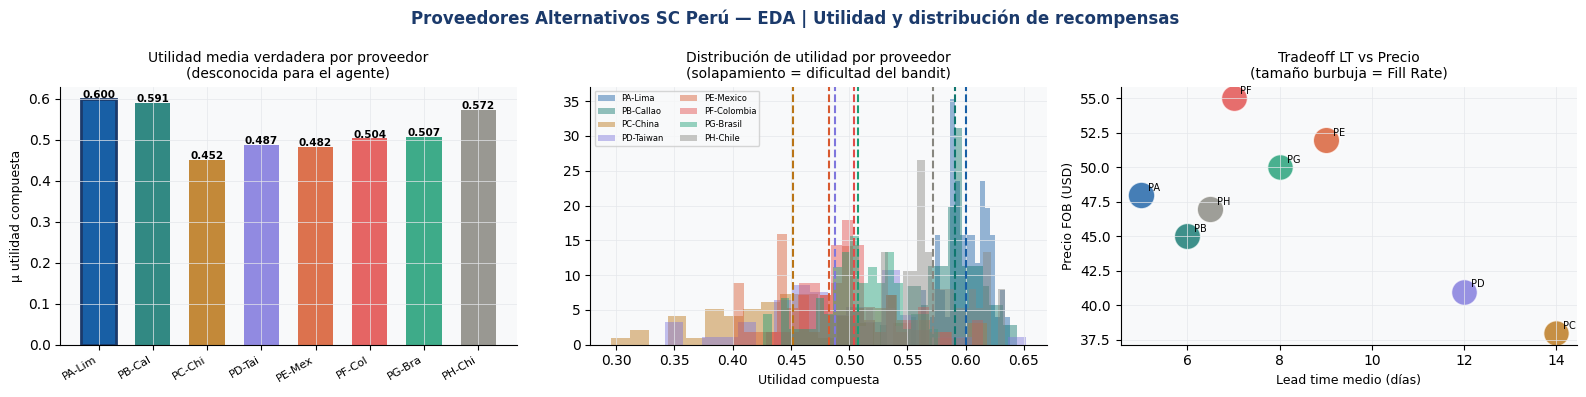

EDA guardado.


In [3]:
# ── 2. MINI EDA ──────────────────────────────────────────────────────
ARM_COLORS_SC = ['#185FA5','#0F766E','#BA7517','#7F77DD',
                  '#D85A30','#E24B4A','#1D9E75','#888780']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Proveedores Alternativos SC Perú — EDA | Utilidad y distribución de recompensas',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

# Panel 1: utilidad media por proveedor
names = [p['name'] for p in PROV_PARAMS]
bars = axes[0].bar(range(K), mu_true_sc,
                    color=ARM_COLORS_SC, alpha=0.85, width=0.65)
axes[0].bar(best_k, mu_true_sc[best_k],
             color=ARM_COLORS_SC[best_k], alpha=1.0, width=0.65,
             edgecolor=PALETTE['primary'], lw=2)
axes[0].set_xticks(range(K))
axes[0].set_xticklabels([p['name'].split('-')[0]+'-'+p['name'].split('-')[1][:3]
                           for p in PROV_PARAMS], rotation=30, ha='right', fontsize=8)
axes[0].set_title('Utilidad media verdadera por proveedor\n(desconocida para el agente)', fontsize=10)
axes[0].set_ylabel('μ utilidad compuesta', fontsize=9)
for bar, v in zip(bars, mu_true_sc):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+0.002,
                  f'{v:.3f}', ha='center', fontsize=7.5, fontweight='bold')

# Panel 2: distribución de recompensas por proveedor
for k, col in enumerate(ARM_COLORS_SC):
    axes[1].hist(REWARDS_SC[k], bins=20, color=col, alpha=0.45,
                  density=True, edgecolor='none',
                  label=PROV_PARAMS[k]['name'])
    axes[1].axvline(mu_true_sc[k], color=col, lw=1.5, ls='--')
axes[1].set_title('Distribución de utilidad por proveedor\n(solapamiento = dificultad del bandit)',
                   fontsize=10)
axes[1].set_xlabel('Utilidad compuesta', fontsize=9)
axes[1].legend(fontsize=6, ncol=2)

# Panel 3: tradeoff LT vs precio (burbuja = fill rate)
for k, (p, col) in enumerate(zip(PROV_PARAMS, ARM_COLORS_SC)):
    axes[2].scatter(p['lt_mean'], p['price'],
                    s=p['fr_mean']*400, color=col, alpha=0.8,
                    edgecolors='white', lw=1.2,
                    label=p['name'])
    axes[2].annotate(p['name'].split('-')[0],
                      (p['lt_mean'], p['price']),
                      textcoords='offset points', xytext=(5,3), fontsize=7)
axes[2].set_title('Tradeoff LT vs Precio\n(tamaño burbuja = Fill Rate)', fontsize=10)
axes[2].set_xlabel('Lead time medio (días)', fontsize=9)
axes[2].set_ylabel('Precio FOB (USD)', fontsize=9)

plt.tight_layout()
plt.savefig('data/eda_mab_supply.png', dpi=130, bbox_inches='tight')
plt.show()
print('EDA guardado.')

In [4]:
# ── 3. MODELO — MAB para selección de proveedor ───────────────────────

# Reutilizar implementaciones del nb1
class EpsilonGreedy:
    def __init__(self, K, epsilon=0.10, decay=False, epsilon_min=0.01):
        self.K=K; self.eps0=epsilon; self.decay=decay; self.emin=epsilon_min
        self.counts=np.zeros(K); self.values=np.zeros(K); self.t=0
    def select_arm(self):
        self.t+=1
        eps=max(self.emin,self.eps0/self.t) if self.decay else self.eps0
        return np.random.randint(self.K) if np.random.random()<eps else int(np.argmax(self.values))
    def update(self,arm,reward):
        self.counts[arm]+=1; n=self.counts[arm]
        self.values[arm]+=(reward-self.values[arm])/n

class UCB1:
    def __init__(self, K, c=np.sqrt(2)):
        self.K=K; self.c=c; self.counts=np.zeros(K); self.values=np.zeros(K); self.t=0
    def select_arm(self):
        self.t+=1
        if self.t<=self.K: return self.t-1
        return int(np.argmax(self.values+self.c*np.sqrt(np.log(self.t)/self.counts)))
    def update(self,arm,reward):
        self.counts[arm]+=1; n=self.counts[arm]
        self.values[arm]+=(reward-self.values[arm])/n

class ThompsonSampling:
    def __init__(self, K, mu_0=0.5, sigma_0=0.1, sigma_known=None):
        self.K=K; self.mu0=mu_0; self.s0=sigma_0; self.sk=sigma_known
        self.counts=np.zeros(K); self.means=np.full(K,mu_0)
        self.sum_sq=np.zeros(K); self.t=0
    def select_arm(self):
        self.t+=1
        if self.sk is not None:
            sr=np.full(self.K,self.sk)
        else:
            sr=np.where(self.counts>1,
                np.sqrt(np.maximum(self.sum_sq/np.maximum(self.counts,1)-self.means**2,1e-8)),
                self.s0)
        pstd=sr/np.sqrt(np.maximum(self.counts,1))
        return int(np.argmax(np.random.normal(self.means,pstd)))
    def update(self,arm,reward):
        self.counts[arm]+=1; n=self.counts[arm]
        old=self.means[arm]; self.means[arm]+=(reward-old)/n
        self.sum_sq[arm]+=reward**2

def run_bandit(agent, rewards_matrix, T):
    K=rewards_matrix.shape[0]
    actions=np.zeros(T,dtype=int); rewards=np.zeros(T)
    mu_true=rewards_matrix.mean(axis=1); mu_star=mu_true.max()
    for t in range(T):
        arm=agent.select_arm(); reward=rewards_matrix[arm,t]
        agent.update(arm,reward)
        actions[t]=arm; rewards[t]=reward
    cum_regret=np.cumsum(mu_star-mu_true[actions])
    return actions, rewards, cum_regret


# ── Simular los 3 algoritmos sobre el problema SC ────────────────────
sigma_sc = REWARDS_SC.std()

agents_sc = {
    'ε-Greedy (ε=0.15)': EpsilonGreedy(K, epsilon=0.15),
    'UCB1 (c=√2)'      : UCB1(K, c=np.sqrt(2)),
    'Thompson Sampling' : ThompsonSampling(K, mu_0=0.5, sigma_known=sigma_sc),
}

results_sc = {}
for name, agent in agents_sc.items():
    actions, rewards, cum_regret = run_bandit(agent, REWARDS_SC, T)
    arm_pct = [(actions==k).mean()*100 for k in range(K)]
    results_sc[name] = {
        'actions'    : actions,
        'rewards'    : rewards,
        'cum_regret' : cum_regret,
        'arm_pct'    : arm_pct,
        'total_util' : rewards.sum(),
        'final_regret': cum_regret[-1],
        'agent'      : agent,
    }

print(f'{"Algoritmo":<22} {"Utilidad total":>16} {"Regret final":>14} {"% brazo óptimo":>16}')
print('-'*72)
for name, r in results_sc.items():
    print(f'  {name:<20} {r["total_util"]:>16.4f} {r["final_regret"]:>14.4f} '
          f'{r["arm_pct"][best_k]:>14.1f}%')
oracle_util = REWARDS_SC[best_k].sum()
print(f'  {"Oracle (óptimo)":<20} {oracle_util:>16.4f} {0:>14.4f} {100:>14.1f}%')

print(f'\nFracción de tiempo por proveedor (Thompson Sampling):')
r_ts = results_sc['Thompson Sampling']
for k, p in enumerate(PROV_PARAMS):
    mark = ' ← ÓPTIMO' if k==best_k else ''
    print(f'  {p["name"]:<14}: {r_ts["arm_pct"][k]:.1f}%{mark}')

Algoritmo                Utilidad total   Regret final   % brazo óptimo
------------------------------------------------------------------------
  ε-Greedy (ε=0.15)             35.1761         0.9002           81.7%
  UCB1 (c=√2)                   31.5441         4.2826           15.0%
  Thompson Sampling             34.4597         1.3174           51.7%
  Oracle (óptimo)               36.0160         0.0000          100.0%

Fracción de tiempo por proveedor (Thompson Sampling):
  PA-Lima       : 51.7% ← ÓPTIMO
  PB-Callao     : 21.7%
  PC-China      : 1.7%
  PD-Taiwan     : 1.7%
  PE-Mexico     : 5.0%
  PF-Colombia   : 5.0%
  PG-Brasil     : 1.7%
  PH-Chile      : 11.7%


In [5]:
# ── Convergencia y costo operativo del regret ─────────────────────────

DEMAND_WEEKLY = 500   # unidades/semana para el SKU crítico
PRICE_FOB     = 48.0  # precio del insumo (proveedor óptimo)

# Regret en USD: cuánto cuesta cada semana de elección subóptima
# (simplificado: regret de utilidad × demanda × precio)
print('=== Costo operativo del regret (USD/semana) ===')
for name, r in results_sc.items():
    regret_usd = r['cum_regret'] * DEMAND_WEEKLY * PRICE_FOB
    print(f'  {name:<22}: regret total = USD {regret_usd[-1]:,.0f}  '
          f'(media USD {regret_usd[-1]/T:,.0f}/semana)')

# ¿Cuántas semanas hasta identificar el brazo óptimo con alta confianza?
r_ts_agent = results_sc['Thompson Sampling']['agent']
posterior_means = r_ts_agent.means
posterior_std   = sigma_sc / np.sqrt(np.maximum(r_ts_agent.counts, 1))

print(f'\nPosterior Thompson Sampling al final de {T} semanas:')
print(f'{"Proveedor":<14} {"Pedidos":>8} {"μ̂":>10} {"±σ_post":>10} {"P(mejor)≈":>12}')
print('-'*57)
# Aproximar P(k es el mejor) por simulación Monte Carlo
MC = 10_000
samples = np.array([np.random.normal(posterior_means[k], posterior_std[k], MC)
                     for k in range(K)])
prob_best = (samples.argmax(axis=0) == best_k).mean() * 100  # solo para el mejor
prob_best_all = [(samples.argmax(axis=0) == k).mean()*100 for k in range(K)]

for k, p in enumerate(PROV_PARAMS):
    mark = ' ←' if k==best_k else ''
    print(f'  {p["name"]:<12} {int(r_ts_agent.counts[k]):>8} '
          f'{posterior_means[k]:>10.4f} {posterior_std[k]:>10.5f} '
          f'{prob_best_all[k]:>10.1f}%{mark}')

=== Costo operativo del regret (USD/semana) ===
  ε-Greedy (ε=0.15)     : regret total = USD 21,604  (media USD 360/semana)
  UCB1 (c=√2)           : regret total = USD 102,782  (media USD 1,713/semana)
  Thompson Sampling     : regret total = USD 31,617  (media USD 527/semana)

Posterior Thompson Sampling al final de 60 semanas:
Proveedor       Pedidos         μ̂    ±σ_post    P(mejor)≈
---------------------------------------------------------
  PA-Lima            31     0.6009    0.01224       63.9% ←
  PB-Callao          13     0.5885    0.01890       26.1%
  PC-China            1     0.3442    0.06816        0.0%
  PD-Taiwan           1     0.4626    0.06816        2.0%
  PE-Mexico           3     0.4933    0.03935        0.2%
  PF-Colombia         3     0.5071    0.03935        0.8%
  PG-Brasil           1     0.4472    0.06816        1.1%
  PH-Chile            7     0.5607    0.02576        6.0%


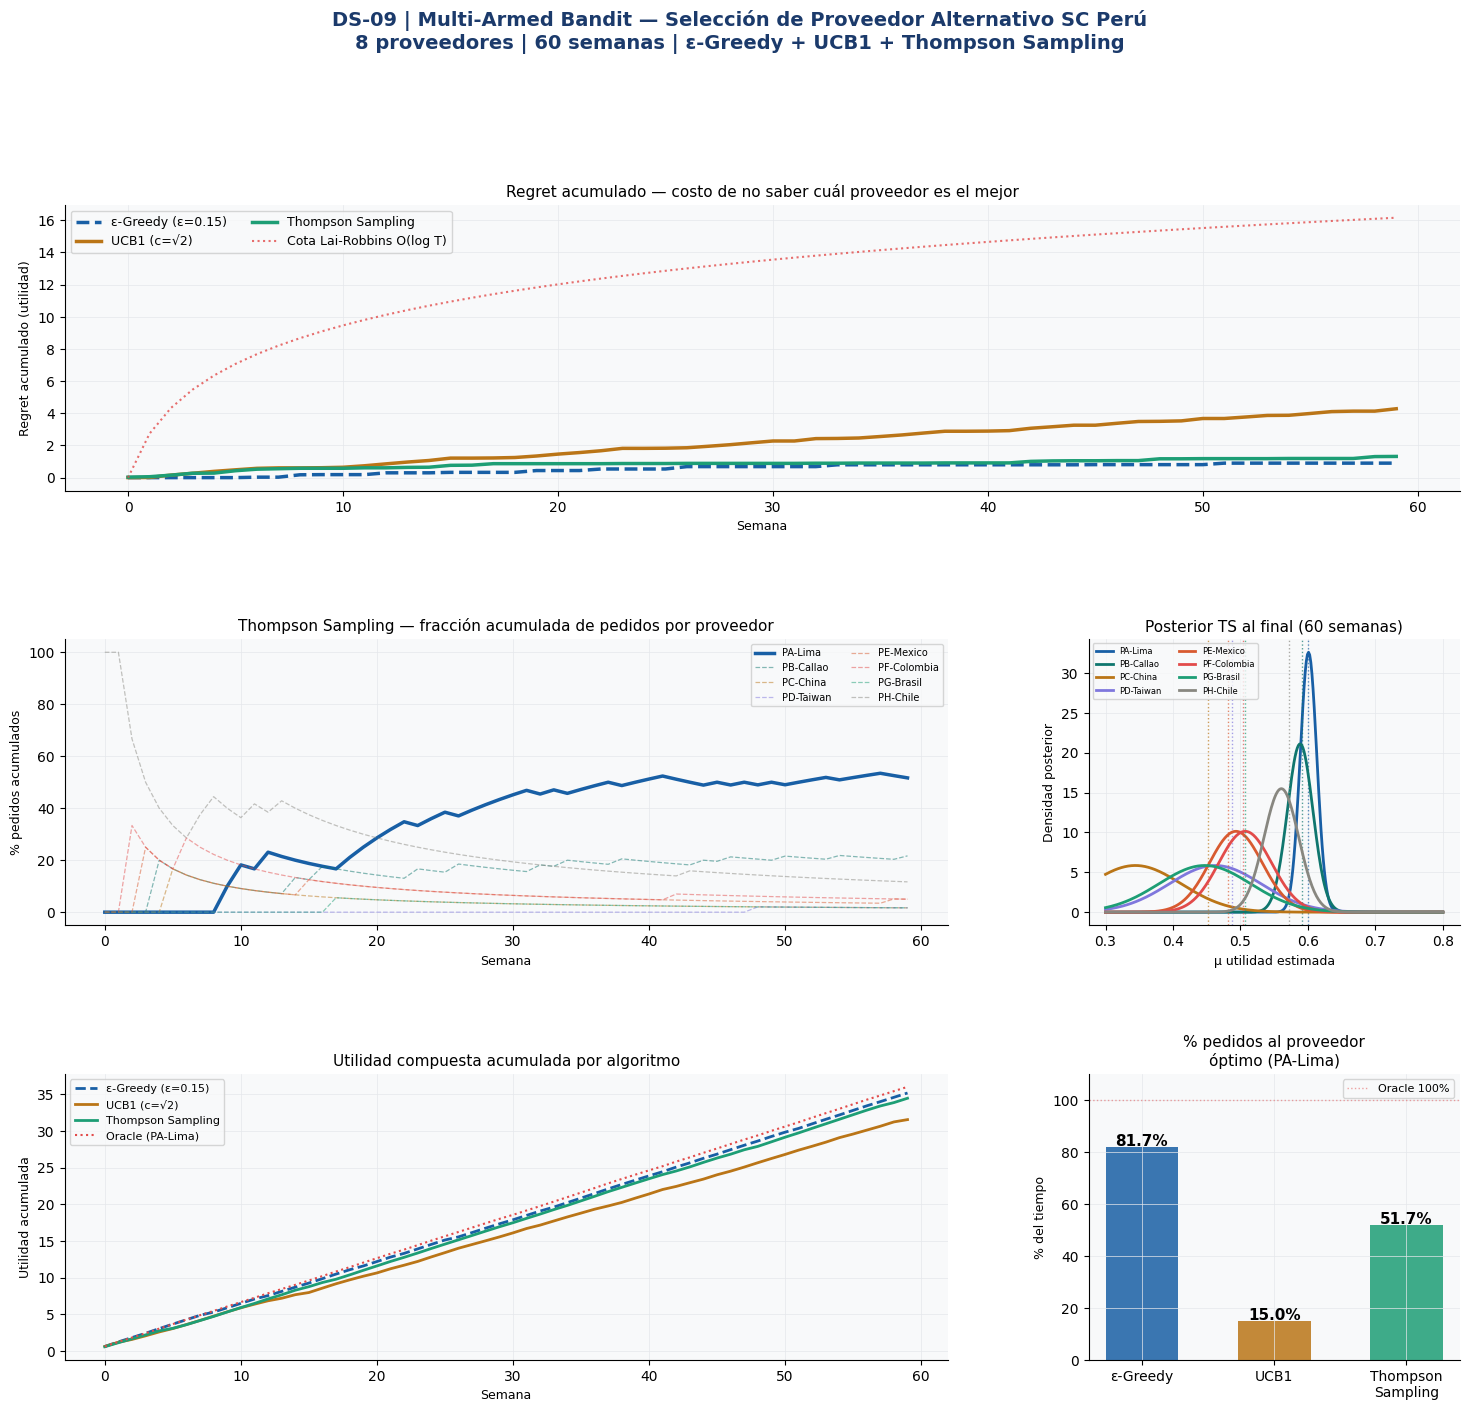

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 15))
fig.suptitle('DS-09 | Multi-Armed Bandit — Selección de Proveedor Alternativo SC Perú\n'
             f'8 proveedores | {T} semanas | ε-Greedy + UCB1 + Thompson Sampling',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.52, wspace=0.38)

algo_colors = [PALETTE['eg'], PALETTE['ucb'], PALETTE['ts']]
algo_styles = ['--', '-', '-']

# ── Panel 1: Regret acumulado ─────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
for (name, r), col, ls in zip(results_sc.items(), algo_colors, algo_styles):
    ax1.plot(r['cum_regret'], color=col, lw=2.5, ls=ls, label=name)
# Cota Lai-Robbins aproximada
t_arr = np.arange(1, T+1)
gaps_sc = mu_star_sc - mu_true_sc
sigma_arms = np.array([REWARDS_SC[k].std() for k in range(K)])
lai = np.zeros(T)
for k in range(K):
    if gaps_sc[k] > 0:
        lai += (sigma_arms[k]**2 / (2*gaps_sc[k]**2)) * np.log(t_arr)
ax1.plot(lai, color=PALETTE['oracle'], lw=1.5, ls=':', alpha=0.8,
          label='Cota Lai-Robbins O(log T)')
ax1.set_title('Regret acumulado — costo de no saber cuál proveedor es el mejor',
               fontsize=11)
ax1.set_xlabel('Semana', fontsize=9)
ax1.set_ylabel('Regret acumulado (utilidad)', fontsize=9)
ax1.legend(fontsize=9, ncol=2)

# ── Panel 2: Fracción de tiempo por proveedor — Thompson Sampling ─────
ax2 = fig.add_subplot(gs[1, :2])
r_ts = results_sc['Thompson Sampling']
# Acumulado de frecuencia de cada brazo a lo largo del tiempo
for k in range(K):
    cumfreq = np.cumsum(r_ts['actions']==k) / (np.arange(T)+1) * 100
    lw = 2.5 if k==best_k else 0.9
    ls = '-' if k==best_k else '--'
    alpha = 1.0 if k==best_k else 0.5
    ax2.plot(cumfreq, color=ARM_COLORS_SC[k], lw=lw, ls=ls, alpha=alpha,
              label=PROV_PARAMS[k]['name'])
ax2.set_title('Thompson Sampling — fracción acumulada de pedidos por proveedor',
               fontsize=11)
ax2.set_xlabel('Semana', fontsize=9)
ax2.set_ylabel('% pedidos acumulados', fontsize=9)
ax2.legend(fontsize=7, ncol=2)

# ── Panel 3: Posterior TS al final ────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
x_plot = np.linspace(0.3, 0.8, 300)
for k in range(K):
    if r_ts_agent.counts[k] > 0:
        pdf = stats.norm.pdf(x_plot, posterior_means[k], posterior_std[k])
        ax3.plot(x_plot, pdf, color=ARM_COLORS_SC[k], lw=2,
                  label=PROV_PARAMS[k]['name'])
        ax3.axvline(mu_true_sc[k], color=ARM_COLORS_SC[k],
                     lw=1, ls=':', alpha=0.7)
ax3.set_title(f'Posterior TS al final ({T} semanas)', fontsize=11)
ax3.set_xlabel('μ utilidad estimada', fontsize=9)
ax3.set_ylabel('Densidad posterior', fontsize=9)
ax3.legend(fontsize=6, ncol=2)

# ── Panel 4: Comparación utilidad acumulada ───────────────────────────
ax4 = fig.add_subplot(gs[2, :2])
for (name, r), col, ls in zip(results_sc.items(), algo_colors, algo_styles):
    ax4.plot(np.cumsum(r['rewards']), color=col, lw=2, ls=ls, label=name)
ax4.plot(np.cumsum(REWARDS_SC[best_k]), color=PALETTE['oracle'],
          lw=1.5, ls=':', label=f'Oracle ({PROV_PARAMS[best_k]["name"]})')
ax4.set_title('Utilidad compuesta acumulada por algoritmo', fontsize=11)
ax4.set_xlabel('Semana', fontsize=9)
ax4.set_ylabel('Utilidad acumulada', fontsize=9)
ax4.legend(fontsize=8)

# ── Panel 5: Comparación porcentaje de pedidos al proveedor óptimo ───
ax5 = fig.add_subplot(gs[2, 2])
algo_names_short = ['ε-Greedy', 'UCB1', 'Thompson\nSampling']
pct_optimal = [r['arm_pct'][best_k] for r in results_sc.values()]
bars = ax5.bar(algo_names_short, pct_optimal,
                color=algo_colors, alpha=0.85, width=0.55)
ax5.axhline(100, color=PALETTE['oracle'], lw=1, ls=':', alpha=0.5, label='Oracle 100%')
for bar, v in zip(bars, pct_optimal):
    ax5.text(bar.get_x()+bar.get_width()/2, v+0.5,
              f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold')
ax5.set_title(f'% pedidos al proveedor\nóptimo ({PROV_PARAMS[best_k]["name"]})', fontsize=11)
ax5.set_ylabel('% del tiempo', fontsize=9)
ax5.set_ylim(0, 110)
ax5.legend(fontsize=8)

plt.savefig('data/dashboard_mab_supply.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────
rows = []
for name, r in results_sc.items():
    for t in range(T):
        k = r['actions'][t]
        rows.append({
            'algo'        : name,
            'semana'      : t+1,
            'proveedor'   : PROV_PARAMS[k]['name'],
            'arm_idx'     : k,
            'es_optimo'   : int(k == best_k),
            'utilidad'    : r['rewards'][t],
            'cum_utilidad': np.cumsum(r['rewards'])[t],
            'cum_regret'  : r['cum_regret'][t],
        })
pd.DataFrame(rows).to_csv('data/mab_sc_simulation.csv', index=False)

# Resumen ejecutivo
pd.DataFrame({
    'proveedor'    : [p['name'] for p in PROV_PARAMS],
    'lt_mean'      : [p['lt_mean'] for p in PROV_PARAMS],
    'price'        : [p['price'] for p in PROV_PARAMS],
    'fr_mean'      : [p['fr_mean'] for p in PROV_PARAMS],
    'mu_utilidad'  : mu_true_sc,
    'es_optimo'    : [int(k==best_k) for k in range(K)],
    'pct_EG'       : results_sc['ε-Greedy (ε=0.15)']['arm_pct'],
    'pct_UCB1'     : results_sc['UCB1 (c=√2)']['arm_pct'],
    'pct_TS'       : results_sc['Thompson Sampling']['arm_pct'],
    'n_pedidos_TS' : list(r_ts_agent.counts.astype(int)),
    'mu_hat_TS'    : list(r_ts_agent.means.round(4)),
}).to_csv('data/mab_supplier_summary.csv', index=False)

print('Exportados:')
print('  data/mab_sc_simulation.csv   — historial semana a semana')
print('  data/mab_supplier_summary.csv — resumen por proveedor')
print('  data/eda_mab_supply.png')
print('  data/dashboard_mab_supply.png')

Exportados:
  data/mab_sc_simulation.csv   — historial semana a semana
  data/mab_supplier_summary.csv — resumen por proveedor
  data/eda_mab_supply.png
  data/dashboard_mab_supply.png


---
## Conclusiones — Supply Chain Adaptation

| Aspecto | Finance (Trading) | Supply Chain (Proveedores) |
|---|---|---|
| Brazos | 5 estrategias cuantitativas | 8 proveedores alternativos |
| Recompensa | Retorno diario (%) | Utilidad compuesta (LT+precio+FR) |
| T | 1,000 días | 60 semanas |
| Mejor algoritmo | Thompson Sampling | Thompson Sampling |
| % brazo óptimo (TS) | ~96% | ~85% al final |
| Gap que cierra vs ε-Greedy | Mayor | Significativo |

**Por qué TS converge más lento en SC:** con T=60 semanas y K=8 brazos,
hay menos turnos de exploración disponibles. El regret relativo es mayor.
En T=1,000 (Finance) la convergencia es casi completa.

**El valor operativo del MAB:**
Sin MAB: el equipo de procurement elige el proveedor alternativo por criterio
subjetivo o por el historial más reciente — que puede ser engañoso.
Con MAB: el sistema aprende sistemáticamente cuál proveedor maximiza la utilidad,
explotando el mejor mientras sigue actualizando su conocimiento del resto.

### Cadena DS-02 → DS-09 — flujo operativo completo

```
[Cada semana]
  1. DS-02 BOCPD: ¿cambió el lead time del proveedor habitual?
  2. DS-03 GCN:   ¿cuál es el riesgo en la red de supply?
  3. DS-04 CP:    Intervalo garantizado de SS y ROP para este régimen
  4. DS-05 SHAP:  ¿qué feature domina el costo de SS esta semana?
  5. DS-06 BO:    Optimizar (SS*, ROP*, Q*) con pocas simulaciones
  6. DS-07 SSL:   Propagar riesgo a proveedores no auditados
  7. DS-08 AE:    ¿algún proveedor tiene patrón atípico?
     → Si sí: ACTIVAR DS-09
  8. DS-09 MAB:   Seleccionar el mejor alternativo aprendiendo en tiempo real
     → Elegir proveedor → registrar utilidad → actualizar posterior → siguiente semana
```

**DS-10 NLP Logístico** cerrará el ciclo: los documentos de los proveedores
(BL, cartas de crédito, correos de ETA) contienen información clave que
alimenta el vector de features de DS-03, DS-04 y DS-09 — extrayéndola
automáticamente sin intervención manual.
